# Proyecto 5. Clasificación de flores

**Objetivo:** Adaptar ResNet18 preentrenada mediante transferencia de aprendizaje.

Ejecuten las celdas en orden. Después de **cada celda de código**, respondan las preguntas en la celda de texto siguiente. Guarden evidencia de sus experimentos y justifiquen cada decisión con resultados y fuentes consultadas. Reinicien el entorno y ejecuten todo antes de entregar.

**Entorno:** Google Colab o Python con Jupyter. Instalen una versión compatible de PyTorch y torchvision, además de numpy, matplotlib, pandas, scikit-learn y datasets cuando corresponda. En Colab pueden usar una celda separada con `%pip install torch torchvision numpy matplotlib pandas scikit-learn datasets`; reinicien el entorno si se les solicita. Descargar datos o pesos requiere internet. Oxford Flowers 102 y pesos de ResNet18 se descargan desde torchvision; requiere internet y espacio en disco.

## 1. Importaciones y reproducibilidad

Importamos las herramientas y fijamos una semilla. Los resultados pueden variar según hardware y versiones.

In [1]:
import random  # Controla el generador aleatorio estándar.
import numpy as np  # Proporciona arreglos y operaciones numéricas.
import matplotlib.pyplot as plt  # Permite construir gráficas.
import torch  # Proporciona tensores y operaciones para redes neuronales.
from torch import nn  # Contiene capas y funciones de pérdida.
from torch.utils.data import DataLoader, Dataset, random_split  # Permite crear lotes y conjuntos de datos.
from pathlib import Path  # Facilita el manejo de rutas.
random.seed(42)  # Fija la semilla de Python.
np.random.seed(42)  # Fija la semilla de NumPy.
torch.manual_seed(42)  # Fija la semilla inicial de PyTorch.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # Selecciona GPU cuando está disponible.
print('Dispositivo:', device, '| PyTorch:', torch.__version__)  # Muestra el entorno de ejecución.


Dispositivo: cpu | PyTorch: 2.14.0+cu130


### Respuestas

1. `random` y NumPy manejan azar y arreglos; Matplotlib grafica; PyTorch aporta tensores, autograd, capas y optimización; `torchvision` contiene Flowers102, transformaciones y ResNet18; scikit-learn calcula métricas; `pathlib` maneja rutas. `torch.device` permite seleccionar CPU o CUDA para ejecutar modelo y tensores en el mismo dispositivo. En la plantilla se importan `Dataset` y `random_split`, aunque la división oficial de Flowers102 hace innecesario usarlos.
2. Hay dos registros con hardware distinto y conviene no mezclarlos. En `Datos/05_flores_datos.ipynb` (CPU, PyTorch 2.15.0) la configuración base con semilla 42 obtuvo 0.7794 en dos repeticiones; semilla 7 obtuvo 0.7951, diferencia de 1.57 puntos porcentuales. En `Arquitectura` (GPU Tesla T4) B0 obtuvo 75.6863% y la semilla 7, 76.3725%, diferencia de 0.6862 puntos. En cada entorno, la semilla 42 se repitió en la muestra registrada; eso no garantiza reproducibilidad entre hardware, versiones o kernels. Solo hay una corrida por semilla alternativa, así que la variación no es una estimación estadística sólida.

Fuentes: ejecución y resultados en la rama `Datos`, y notebook GPU ejecutado en `Arquitectura`.

## 2. Datos y conjuntos

Preparen entrenamiento, validación y prueba sin mezclar información entre ellos. La validación sirve para decisiones; la prueba se reserva para la evaluación final.

In [2]:
from torchvision import datasets, transforms, models  # Importa datasets, transformaciones y modelos de visión.
pesos = models.ResNet18_Weights.DEFAULT  # Selecciona los pesos preentrenados oficiales.
transformacion = pesos.transforms()  # Aplica el tamaño y normalización esperados por dichos pesos.
entrenamiento = datasets.Flowers102('datos', split='train', download=True, transform=transformacion)  # Descarga y prepara entrenamiento.
validacion = datasets.Flowers102('datos', split='val', download=True, transform=transformacion)  # Carga validación independiente.
prueba = datasets.Flowers102('datos', split='test', download=True, transform=transformacion)  # Carga prueba independiente.
clases = [f'Flor {i+1}' for i in range(102)]  # Usa identificadores de clase; consulten el catálogo para nombres botánicos.
train_loader = DataLoader(entrenamiento, batch_size=32, shuffle=True)  # Forma lotes mezclados para entrenamiento.
val_loader = DataLoader(validacion, batch_size=32)  # Forma lotes para validación.
test_loader = DataLoader(prueba, batch_size=32)  # Forma lotes para prueba.
print('Clases:', clases, '| tamaños:', len(entrenamiento), len(validacion), len(prueba))  # Muestra las clases y particiones.


Clases: ['Flor 1', 'Flor 2', 'Flor 3', 'Flor 4', 'Flor 5', 'Flor 6', 'Flor 7', 'Flor 8', 'Flor 9', 'Flor 10', 'Flor 11', 'Flor 12', 'Flor 13', 'Flor 14', 'Flor 15', 'Flor 16', 'Flor 17', 'Flor 18', 'Flor 19', 'Flor 20', 'Flor 21', 'Flor 22', 'Flor 23', 'Flor 24', 'Flor 25', 'Flor 26', 'Flor 27', 'Flor 28', 'Flor 29', 'Flor 30', 'Flor 31', 'Flor 32', 'Flor 33', 'Flor 34', 'Flor 35', 'Flor 36', 'Flor 37', 'Flor 38', 'Flor 39', 'Flor 40', 'Flor 41', 'Flor 42', 'Flor 43', 'Flor 44', 'Flor 45', 'Flor 46', 'Flor 47', 'Flor 48', 'Flor 49', 'Flor 50', 'Flor 51', 'Flor 52', 'Flor 53', 'Flor 54', 'Flor 55', 'Flor 56', 'Flor 57', 'Flor 58', 'Flor 59', 'Flor 60', 'Flor 61', 'Flor 62', 'Flor 63', 'Flor 64', 'Flor 65', 'Flor 66', 'Flor 67', 'Flor 68', 'Flor 69', 'Flor 70', 'Flor 71', 'Flor 72', 'Flor 73', 'Flor 74', 'Flor 75', 'Flor 76', 'Flor 77', 'Flor 78', 'Flor 79', 'Flor 80', 'Flor 81', 'Flor 82', 'Flor 83', 'Flor 84', 'Flor 85', 'Flor 86', 'Flor 87', 'Flor 88', 'Flor 89', 'Flor 90', 'Flor 91',

### Respuestas

1. La división oficial de Oxford Flowers 102 tiene 1,020 imágenes de entrenamiento (10 por clase), 1,020 de validación (10 por clase) y 6,149 de prueba (20–238 por clase), para 102 clases. Entrenamiento ajusta pesos, validación sirve para elegir configuraciones y prueba queda para la evaluación final. La rama `Datos` también midió tamaños originales: ancho 500–919 px y alto 500–993 px. Con los pesos de ResNet18 las imágenes pasan a RGB `(3,224,224)`; un lote de 32 queda con forma `(32,3,224,224)`. La transformación redimensiona el lado corto a 256, recorta 224 × 224 y normaliza con medias y desviaciones de ImageNet. La prueba desbalanceada puede hacer que la exactitud global dé más peso a las clases numerosas.
2. No debemos ajustar con prueba porque dejaría de ser una evaluación de datos no vistos. En la corrida CPU de `Datos`, lote 32 obtuvo 0.7794 y lote 64 obtuvo 0.7451 (−3.43 puntos); los dos tardaron alrededor de 3.5 min. En el registro GPU de `Arquitectura`, la validación pasó de 75.6863% a 73.4314% (−2.2549 puntos) y el tiempo de 65.29 a 60.63 s. Son mediciones en entornos distintos, no una comparación directa. Con 1,020 ejemplos, cada época tiene 32 lotes de tamaño 32 o 16 de tamaño 64; en cinco épocas son 160 frente a 80 actualizaciones. Menos actualizaciones puede explicar parte de la diferencia, pero una corrida por configuración no demuestra la causa.

Fuentes: exploración y prueba CPU en `Datos/05_flores_datos.ipynb`; comparación GPU en `Arquitectura/notebooks/Arquitectura_ResNet18_GPU_ejecutado.ipynb`.

## 3. Arquitectura y entrenamiento

El modelo recibe imágenes preparadas con la transformación asociada a sus pesos.

In [3]:
modelo = models.resnet18(weights=pesos)  # Carga la red con conocimientos preentrenados.
for parametro in modelo.parameters():  # Recorre todos los parámetros de la red.
    parametro.requires_grad = False  # Impide actualizar los parámetros originales.
entradas = modelo.fc.in_features  # Consulta el tamaño de la representación anterior al clasificador.
modelo.fc = nn.Linear(entradas, len(clases))  # Sustituye la capa final por una adaptada al problema.
modelo = modelo.to(device)  # Coloca la red en el dispositivo disponible.
perdida = nn.CrossEntropyLoss()  # Calcula la pérdida para clasificación multiclase.
optimizador = torch.optim.Adam(modelo.fc.parameters(), lr=0.001)  # Entrena solo la nueva capa final.
epocas = 5  # Define las épocas iniciales.
print('Entrada del clasificador:', entradas, '| clases:', len(clases))  # Muestra la adaptación realizada.


Entrada del clasificador: 512 | clases: 102


### Respuestas

1. Flujo de una imagen: `(3,224,224)` → conv1 `(64,112,112)` → maxpool `(64,56,56)` → layer1 `(64,56,56)` → layer2 `(128,28,28)` → layer3 `(256,14,14)` → layer4 `(512,7,7)` → average pool `(512,1,1)` → vector de 512 → capa `Linear(512,102)` con 102 logits. Las dimensiones indicadas no incluyen el tamaño del lote.
2. `CrossEntropyLoss` corresponde a una etiqueta entre 102 clases y recibe logits junto con la clase correcta; internamente combina log-softmax y NLL. ReLU introduce no linealidad en los bloques. Para mostrar probabilidades usamos softmax al final, no antes de la pérdida. Adam ajusta parámetros entrenables; la configuración base y E5 usaron tasa 0.001.
3. Experimentos registrados desde la misma base: bajar la tasa a 0.0001 dio 18.3333% en validación (E3); subir de 5 a 10 épocas dio 83.4314% (E4); descongelar layer4 además de `fc` dio 91.9608% (E5), frente a 75.6863% de B0. E5 fue el mejor de los seis ensayos registrados. Estos números son de la ejecución GPU de la rama, no de una nueva corrida de este notebook.

La arquitectura auditada tenía 11,228,838 parámetros: B0 entrenaba 52,326; E5, 8,446,054. Fuentes: notebook y `docs/Arquitectura_ResNet18.pdf` de la rama `Arquitectura`.

## 4. Ciclo de entrenamiento

En entrenamiento se calculan gradientes y se actualizan parámetros. En validación se desactiva el cálculo de gradientes.

In [4]:
def evaluar(loader):  # Define una función para medir pérdida y exactitud.
    modelo.eval()  # Cambia el modelo al modo de evaluación.
    suma, aciertos, cantidad = 0.0, 0, 0  # Inicializa los acumuladores.
    with torch.no_grad():  # Evita construir el grafo de gradientes.
        for x, y in loader:  # Recorre los lotes del conjunto recibido.
            x, y = x.to(device), y.to(device)  # Mueve entradas y etiquetas al dispositivo.
            logits = modelo(x)  # Calcula las puntuaciones de cada clase.
            suma += perdida(logits, y).item() * y.size(0)  # Acumula la pérdida ponderada por lote.
            aciertos += (logits.argmax(1) == y).sum().item()  # Cuenta predicciones correctas.
            cantidad += y.size(0)  # Cuenta ejemplos procesados.
    return suma / cantidad, aciertos / cantidad  # Devuelve pérdida media y exactitud.
historia = {'train_loss': [], 'val_loss': [], 'val_acc': []}  # Guarda métricas por época.
for epoca in range(epocas):  # Repite el entrenamiento el número de épocas elegido.
    modelo.train()  # Activa el modo de entrenamiento.
    suma, cantidad = 0.0, 0  # Reinicia acumuladores de entrenamiento.
    for x, y in train_loader:  # Recorre los lotes de entrenamiento.
        x, y = x.to(device), y.to(device)  # Lleva el lote al dispositivo.
        optimizador.zero_grad()  # Limpia gradientes de la iteración anterior.
        logits = modelo(x)  # Calcula las puntuaciones de salida.
        error = perdida(logits, y)  # Compara las puntuaciones con las etiquetas.
        error.backward()  # Calcula gradientes mediante backpropagation.
        optimizador.step()  # Actualiza los parámetros entrenables.
        suma += error.item() * y.size(0)  # Acumula la pérdida ponderada.
        cantidad += y.size(0)  # Acumula la cantidad de ejemplos.
    val_loss, val_acc = evaluar(val_loader)  # Evalúa sin actualizar parámetros.
    historia['train_loss'].append(suma / cantidad)  # Registra pérdida de entrenamiento.
    historia['val_loss'].append(val_loss)  # Registra pérdida de validación.
    historia['val_acc'].append(val_acc)  # Registra exactitud de validación.
    print(f'Época {epoca+1}: pérdida={suma/cantidad:.4f}, val={val_loss:.4f}, exactitud={val_acc:.3f}')  # Resume la época.


Época 1: pérdida=4.5701, val=3.7667, exactitud=0.244


Época 2: pérdida=3.1424, val=2.8212, exactitud=0.589


Época 3: pérdida=2.1766, val=2.2138, exactitud=0.669


Época 4: pérdida=1.5284, val=1.7644, exactitud=0.755


Época 5: pérdida=1.0707, val=1.4887, exactitud=0.783


### Respuestas

1. `zero_grad()` borra gradientes anteriores (PyTorch los acumula por defecto); `backward()` deriva la pérdida respecto a los parámetros; `step()` aplica la actualización del optimizador. Si se omite el primero, se acumulan gradientes de lotes; si `step()` ocurre antes de `backward()`, actualiza con gradientes viejos o nulos.
2. `train()` y `eval()` cambian el comportamiento de capas como BatchNorm y Dropout; `no_grad()` evita construir el grafo de gradientes y ahorra memoria durante evaluación. No son intercambiables: evaluación suele usar `eval()` junto con `no_grad()`.
3. En el experimento E4, duplicar de 5 a 10 épocas elevó la exactitud de validación de 75.6863% a 83.4314%; la pérdida de validación terminó en 1.1090 frente a 1.7359 de B0. Bajó globalmente durante las 10 épocas, por lo que esa corrida no muestra evidencia clara de sobreajuste sostenido en ese intervalo. No permite afirmar que entrenar más siempre ayude.

Cifras de la ejecución GPU documentada en la rama `Arquitectura`.

## 5. Curvas y prueba

Utilicen la prueba solo después de tomar sus decisiones con validación.

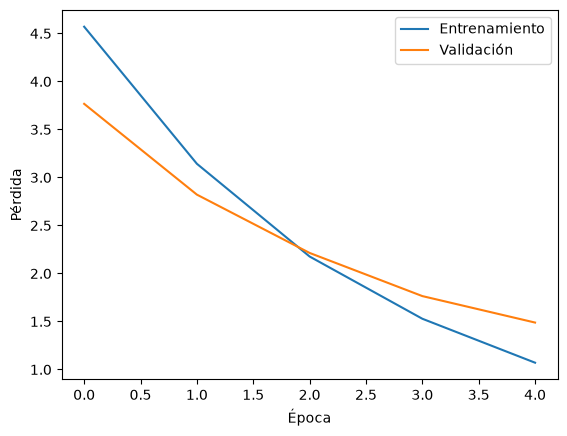

Prueba: pérdida 1.5577 exactitud 0.7549


In [5]:
plt.plot(historia['train_loss'], label='Entrenamiento')  # Dibuja la pérdida de entrenamiento.
plt.plot(historia['val_loss'], label='Validación')  # Dibuja la pérdida de validación.
plt.xlabel('Época')  # Nombra el eje horizontal.
plt.ylabel('Pérdida')  # Nombra el eje vertical.
plt.legend()  # Identifica las curvas.
plt.show()  # Muestra la gráfica.
test_loss, test_acc = evaluar(test_loader)  # Evalúa una vez el conjunto reservado.
print('Prueba: pérdida', round(test_loss, 4), 'exactitud', round(test_acc, 4))  # Muestra los resultados.


### Respuestas

1. En B0 la pérdida bajó tanto en entrenamiento (4.5653 a 1.3747) como en validación (3.8607 a 1.7359) durante cinco épocas. En E5 la pérdida de validación llegó a 0.4631 y la exactitud siguió mejorando hasta la época 5. La brecha entre curvas merece vigilancia, pero sin empeoramiento sostenido de validación no basta para concluir sobreajuste.
2. Exactitud es la fracción de imágenes clasificadas correctamente. Un promedio alto puede ocultar clases difíciles y no indica qué errores se cometen; por eso miramos matriz de confusión y métricas por clase.
3. La comparación registrada en validación fue: B0 75.69%; semilla 7, 76.37%; lote 64, 73.43%; LR 0.0001, 18.33%; 10 épocas, 83.43%; descongelar layer4, 91.96%. Elegimos E5_LAYER4 por la mayor exactitud de validación (y pérdida 0.4631). Después, la evaluación final registrada en las 6,149 imágenes de prueba fue Top-1 88.8600% y Top-3 94.9748%. El informe advierte que se conocían métricas históricas de prueba; no se usaron para seleccionar E5 en esta ejecución. Una repetición independiente sería útil para medir estabilidad.

Fuente: `resultados_experimentos.json` y notebook ejecutado de la rama `Arquitectura` (Tesla T4).

## 6. Errores y matriz de confusión

Las filas indican la clase real y las columnas la predicción.

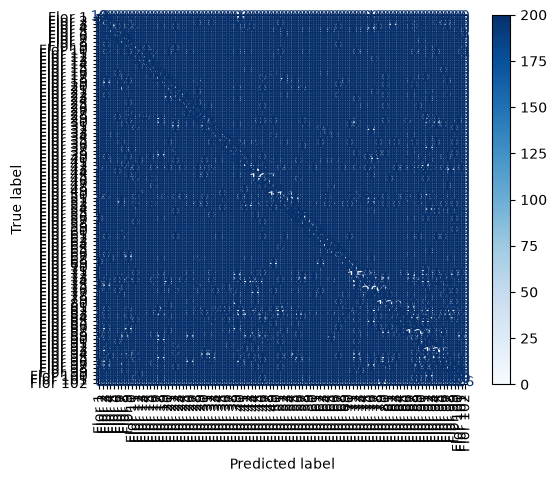

              precision    recall  f1-score   support

      Flor 1       0.41      0.90      0.56        20
      Flor 2       1.00      0.97      0.99        40
      Flor 3       0.08      0.15      0.10        20
      Flor 4       0.78      0.19      0.31        36
      Flor 5       0.89      0.69      0.78        45
      Flor 6       0.77      0.92      0.84        25
      Flor 7       0.44      1.00      0.62        20
      Flor 8       0.80      0.98      0.88        65
      Flor 9       0.41      0.92      0.57        26
     Flor 10       0.88      0.88      0.88        25
     Flor 11       0.54      0.46      0.50        67
     Flor 12       0.88      0.94      0.91        67
     Flor 13       0.87      0.93      0.90        29
     Flor 14       0.88      1.00      0.93        28
     Flor 15       0.78      0.97      0.86        29
     Flor 16       0.44      0.90      0.59        21
     Flor 17       0.98      0.92      0.95        65
     Flor 18       0.46    

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  # Importa herramientas de evaluación.
reales, predichos = [], []  # Prepara listas para etiquetas y predicciones.
modelo.eval()  # Activa el modo de evaluación.
with torch.no_grad():  # Desactiva el cálculo de gradientes.
    for x, y in test_loader:  # Recorre el conjunto de prueba.
        pred = modelo(x.to(device)).argmax(1).cpu()  # Obtiene la clase más probable.
        reales.extend(y.tolist())  # Guarda las etiquetas verdaderas.
        predichos.extend(pred.tolist())  # Guarda las clases predichas.
matriz = confusion_matrix(reales, predichos, labels=list(range(len(clases))))  # Cuenta aciertos y confusiones.
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(xticks_rotation=90, cmap='Blues')  # Grafica la matriz.
plt.show()  # Muestra la matriz.
print(classification_report(reales, predichos, labels=list(range(len(clases))), target_names=clases, zero_division=0))  # Muestra métricas por clase.


### Respuestas

1. La matriz registró con más frecuencia Flor 51 → Flor 83 (31 casos) y Flor 74 → Flor 88 (23). Son conteos observados, no una explicación de por qué ocurre la confusión; para atribuirla a forma, color o encuadre hay que revisar las imágenes concretas.
2. Precisión responde: de las imágenes predichas como una clase, ¿cuántas sí pertenecían a ella? Recall: de las imágenes reales de esa clase, ¿cuántas recuperamos? F1 resume ambas mediante su media armónica. La rama guarda el reporte por clase en `evidencias/metricas_por_clase.csv`.
3. En los tres errores visualizados en la ejecución registrada: Flor 2 se predijo como Flor 52; otra Flor 2 como Flor 7; y Flor 3 como Flor 9. En las dos primeras se observan flores blancas con zonas amarillas, pero distinto encuadre y fondo; la tercera muestra varias corolas moradas y vegetación. Son rasgos visibles que podrían dificultar la clasificación, no causas demostradas. La evidencia está en `evidencias/tres_errores.png`.

Fuente: rama `Arquitectura`, notebook ejecutado y archivos de evidencia.

## 7. Guardado, carga e inferencia

El archivo contiene pesos y metadatos para reproducir la configuración. Conserven también el código y el preprocesamiento.

In [7]:
ruta_modelo = Path('modelo_entrenado.pth')  # Define el nombre del archivo de salida.
torch.save({'pesos': modelo.state_dict(), 'clases': clases}, ruta_modelo)  # Guarda pesos y nombres de clases.
checkpoint = torch.load(ruta_modelo, map_location=device, weights_only=True)  # Carga el archivo confiable en el dispositivo elegido.
modelo.load_state_dict(checkpoint['pesos'])  # Restaura los parámetros en la arquitectura definida.
modelo.eval()  # Prepara la red para inferencia.
x, y = next(iter(test_loader))  # Obtiene un lote que no se usó para entrenar.
with torch.no_grad():  # Desactiva gradientes durante la predicción.
    probabilidades = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Convierte puntuaciones en probabilidades normalizadas.
indice = probabilidades.argmax().item()  # Localiza la clase con mayor puntuación.
print('Real:', clases[y[0].item()], '| Predicción:', clases[indice], '| Confianza:', round(probabilidades[indice].item(), 3))  # Presenta el resultado.


Real: Flor 1 | Predicción: Flor 1 | Confianza: 0.174


### Respuestas

1. Los pesos solo contienen valores numéricos; para interpretarlos hay que reconstruir la misma ResNet18, conservar el orden de las 102 clases y aplicar el preprocesamiento esperado (resize 256, crop 224 y normalización ImageNet). Si cambia una de esas piezas, las entradas o salidas pueden dejar de corresponder al modelo.
2. Softmax convierte logits en valores entre 0 y 1 cuya suma es 1; sirve para ordenar clases y mostrar puntuaciones tipo probabilidad. No garantiza calibración: un modelo puede asignar mucha confianza a una predicción equivocada.
3. En los cinco ejemplos de prueba impresos en la ejecución registrada, la clase real fue Flor 1 y apareció primera en el Top-3; esto solo describe esos cinco, no todo el conjunto. Para comparar el ajuste de `fc` contra fine-tuning, la rama `Arquitectura` registró B0 (solo `fc` entrenable: 52,326 parámetros) con 75.6863% de validación y E5 (descongeló `layer4` y `fc`: 8,446,054 entrenables) con 91.9608%. E5 mejoró 16.2745 puntos porcentuales en esa ejecución. Tras descongelar capas hay que crear de nuevo el optimizador para que incluya sus parámetros.

La comparación de capas procede de la corrida GPU registrada en la rama `Arquitectura`; no se volvió a entrenar aquí.

## Entrega y defensa

Entreguen el notebook ejecutado, modelo, fuentes y reporte. Incluyan una tabla con configuración inicial, modificaciones, métricas y explicación. Respondan todas las preguntas, citen la documentación consultada y expliquen qué cambiarían. No seleccionen hiperparámetros usando prueba.

## 8. Tres clases más probables

Top-3 muestra alternativas; no garantiza que las probabilidades estén calibradas.

In [8]:
x, y = next(iter(test_loader))  # Obtiene un lote de prueba.
with torch.no_grad():  # Evita gradientes durante inferencia.
    p = torch.softmax(modelo(x[:1].to(device)), dim=1)[0].cpu()  # Calcula puntuaciones normalizadas.
valores, indices = p.topk(3)  # Selecciona las tres puntuaciones mayores.
for valor, indice in zip(valores, indices):  # Recorre puntuaciones y clases seleccionadas.
    print(clases[indice.item()], round(valor.item(), 3))  # Muestra cada clase y su confianza.
print('Clase real:', clases[y[0].item()])  # Muestra la etiqueta verdadera.


Flor 1 0.174
Flor 76 0.064
Flor 19 0.047
Clase real: Flor 1


### Respuestas

1. Sí. En los cinco ejemplos de prueba que imprimió la ejecución de referencia, la etiqueta real Flor 1 quedó en primer lugar; por tanto también estuvo entre las tres primeras. Es una muestra de cinco imágenes, no una conclusión sobre todas las clases.
2. Top-1 cuenta acierto solo si la clase correcta ocupa el primer puesto; Top-3 cuenta acierto si aparece entre las tres puntuaciones mayores. En la prueba completa (6,149 imágenes) la corrida registrada obtuvo Top-1 = 88.8600% (5,464 aciertos) y Top-3 = 94.9748%; Top-3 suma 6.1148 puntos. La segunda métrica muestra que en parte de los errores la clase correcta quedó cerca de la predicción principal, pero no sustituye Top-1 ni indica que las puntuaciones estén calibradas.

Estos resultados y el Top-3 calculado para todo test están registrados en `notebooks/Arquitectura_ResNet18_GPU_ejecutado.ipynb`. No son outputs de ejecutar este archivo.

## Fuentes y procedencia de resultados

- Repositorio del proyecto: https://github.com/Chrusthoper/clasificacion-flores-resnet18
- Rama `Datos`: respuestas, exploración del dataset y pruebas CPU de semilla y tamaño de lote, en `05_flores_datos.ipynb`.
- Rama `Arquitectura`: notebook GPU ejecutado, comparación de seis configuraciones, evaluación final, matriz de confusión y artefactos en `evidencias/`.
- Ramas `Entrenamiento_y_experimentos` y `Evaluación_demostración`: al revisar el repositorio apuntaban al mismo commit base que `main` y no contenían cambios propios adicionales; por eso no se les atribuyen resultados que no tienen.
- Oxford VGG Flowers 102: https://www.robots.ox.ac.uk/~vgg/data/flowers/102/
- PyTorch, `torch.device`: https://pytorch.org/docs/stable/tensor_attributes.html#torch.device
- Torchvision, ResNet-18: https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html

Las mediciones CPU de `Datos` y GPU de `Arquitectura` se presentan por separado, ya que corresponden a entornos distintos. Las respuestas sintetizan las evidencias ya guardadas en esas ramas; este archivo no se ejecutó de nuevo.

## 9. Evaluación y demostración (Persona 4)

Este bloque depende de los experimentos: la evaluación final se hace con la configuración que gane en validación. Para no quedarse esperando, queda con `CONFIG = 'base'` (ResNet18 congelada, 5 épocas) y así ya se puede probar toda la ruta de matriz de confusión, errores, guardado y demo. Cuando Persona 3 cierre la comparación, se cambia a `CONFIG = 'final'` y solo se vuelve a correr esta sección: los números y las capturas se actualizan solos.

Lo que no cambia entre una corrida y otra es el código; lo que cambia es el punto de partida del modelo. La prueba se toca aquí una sola vez, después de elegir, nunca para escoger.

In [9]:
# Parámetros de la sección. 'base' sirve para avanzar mientras se decide; 'final' reproduce la configuración ganadora.
CONFIG = 'base'  # Cambiar a 'final' cuando Persona 3 cierre los experimentos.
EPOCAS_EVAL = {'base': 5, 'final': 10}[CONFIG]  # Épocas de la configuración elegida.
DESCONGELAR_LAYER4 = CONFIG == 'final'  # El fine-tuning de layer4 fue el cambio que ganó en validación.
RUTA_EVAL = Path(f'evaluacion_{CONFIG}.pth')  # Checkpoint propio de esta sección.
RUTA_BASE = Path('modelo_entrenado.pth')  # Checkpoint de la sección 7 (solo válido para la configuración base).
REUTILIZAR = RUTA_EVAL.exists() or (CONFIG == 'base' and RUTA_BASE.exists())  # Si ya existe, no se repite el entrenamiento.
print('Configuración:', CONFIG, '| épocas:', EPOCAS_EVAL, '| layer4 entrenable:', DESCONGELAR_LAYER4, '| reutilizar:', REUTILIZAR)

Configuración: base | épocas: 5 | layer4 entrenable: False | reutilizar: True


In [10]:
# Se construye el modelo desde los pesos preentrenados, igual que en la sección 3.
modelo_eval = models.resnet18(weights=pesos)
for parametro in modelo_eval.parameters():
    parametro.requires_grad = False  # Congela el cuerpo convolucional.
modelo_eval.fc = nn.Linear(modelo_eval.fc.in_features, len(clases))  # 102 salidas.
if DESCONGELAR_LAYER4:
    for parametro in modelo_eval.layer4.parameters():
        parametro.requires_grad = True  # Fine-tuning del último bloque.
modelo_eval = modelo_eval.to(device)
optimizador_eval = torch.optim.Adam([p for p in modelo_eval.parameters() if p.requires_grad], lr=0.001)  # Se reconstruye tras descongelar.
criterio_eval = nn.CrossEntropyLoss()
def evaluar_eval(loader):  # Evaluación con el modelo de ESTA sección, no con el global de la sección 4.
    modelo_eval.eval()
    suma, aciertos, cantidad = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = modelo_eval(x)
            suma += criterio_eval(logits, y).item() * y.size(0)
            aciertos += (logits.argmax(1) == y).sum().item()
            cantidad += y.size(0)
    return suma / cantidad, aciertos / cantidad
entrenables_eval = sum(p.numel() for p in modelo_eval.parameters() if p.requires_grad)
print('Parámetros entrenables:', f'{entrenables_eval:,}', '| total:', f'{sum(p.numel() for p in modelo_eval.parameters()):,}')

Parámetros entrenables: 52,326 | total: 11,228,838


In [11]:
# Entrenamiento con seguimiento en validación, o carga del checkpoint si ya existe.
import copy, time
historial_eval = {'train_loss': [], 'val_loss': [], 'val_acc': []}
inicio_eval = time.time()
if REUTILIZAR:
    origen = RUTA_EVAL if RUTA_EVAL.exists() else RUTA_BASE
    estado = torch.load(origen, map_location=device, weights_only=True)
    modelo_eval.load_state_dict(estado['pesos'])
    if 'historial' in estado:
        historial_eval = estado['historial']
    elif 'historia' in globals():  # Reutiliza las curvas de la sección 4.
        historial_eval = {'train_loss': historia['train_loss'], 'val_loss': historia['val_loss'], 'val_acc': historia['val_acc']}
    print('Checkpoint cargado:', origen, '| sin reentrenar')
else:
    mejor_estado, mejor_acc = copy.deepcopy(modelo_eval.state_dict()), -1.0
    for epoca in range(EPOCAS_EVAL):
        modelo_eval.train()
        suma = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizador_eval.zero_grad()
            error = criterio_eval(modelo_eval(x), y)
            error.backward()
            optimizador_eval.step()
            suma += error.item() * y.size(0)
        perdida_val, exactitud_val = evaluar_eval(val_loader)
        historial_eval['train_loss'].append(suma / len(entrenamiento))
        historial_eval['val_loss'].append(perdida_val)
        historial_eval['val_acc'].append(exactitud_val)
        if exactitud_val > mejor_acc:
            mejor_acc, mejor_estado = exactitud_val, copy.deepcopy(modelo_eval.state_dict())
        print(f'Época {epoca+1}/{EPOCAS_EVAL} | train_loss={suma/len(entrenamiento):.4f} | val_loss={perdida_val:.4f} | val_acc={exactitud_val:.4f}')
    modelo_eval.load_state_dict(mejor_estado)  # Se conserva la mejor época por validación.
    torch.save({'pesos': mejor_estado, 'historial': historial_eval, 'config': CONFIG}, RUTA_EVAL)
    print(f'Mejor validación: {mejor_acc:.4f} | guardado en {RUTA_EVAL}')
print('Minutos:', round((time.time() - inicio_eval) / 60, 2))

Checkpoint cargado: modelo_entrenado.pth | sin reentrenar
Minutos: 0.0


In [12]:
# Evaluación única sobre prueba: pérdida, Top-1 y Top-3 en una sola pasada.
modelo_eval.eval()
perdida_total, reales_eval, predichos_eval, top3_eval = 0.0, [], [], 0
with torch.no_grad():
    for x, y in test_loader:
        logits = modelo_eval(x.to(device))
        perdida_total += criterio_eval(logits, y.to(device)).item() * y.size(0)
        top3 = logits.topk(3, dim=1).indices.cpu()
        predichos_eval.extend(logits.argmax(1).cpu().tolist())
        reales_eval.extend(y.tolist())
        top3_eval += (top3 == y.view(-1, 1)).any(1).sum().item()
metricas_eval = {'loss': perdida_total / len(prueba), 'top1': sum(r == p for r, p in zip(reales_eval, predichos_eval)) / len(prueba), 'top3': top3_eval / len(prueba), 'n': len(prueba)}
print('Prueba:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in metricas_eval.items()})
print('Aciertos Top-1:', sum(r == p for r, p in zip(reales_eval, predichos_eval)), '| errores:', len(prueba) - sum(r == p for r, p in zip(reales_eval, predichos_eval)))

Prueba: {'loss': 1.5577, 'top1': 0.7549, 'top3': 0.8767, 'n': 6149}
Aciertos Top-1: 4642 | errores: 1507


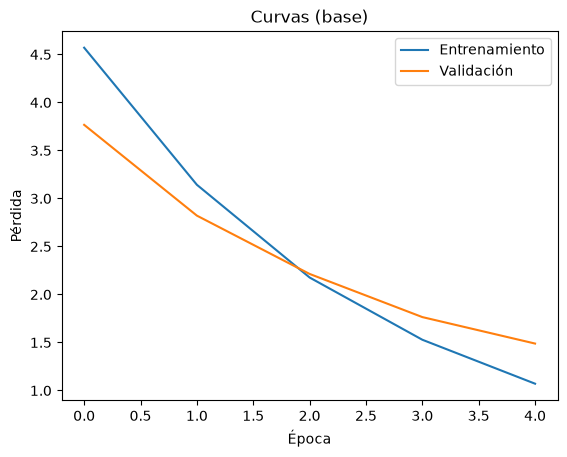

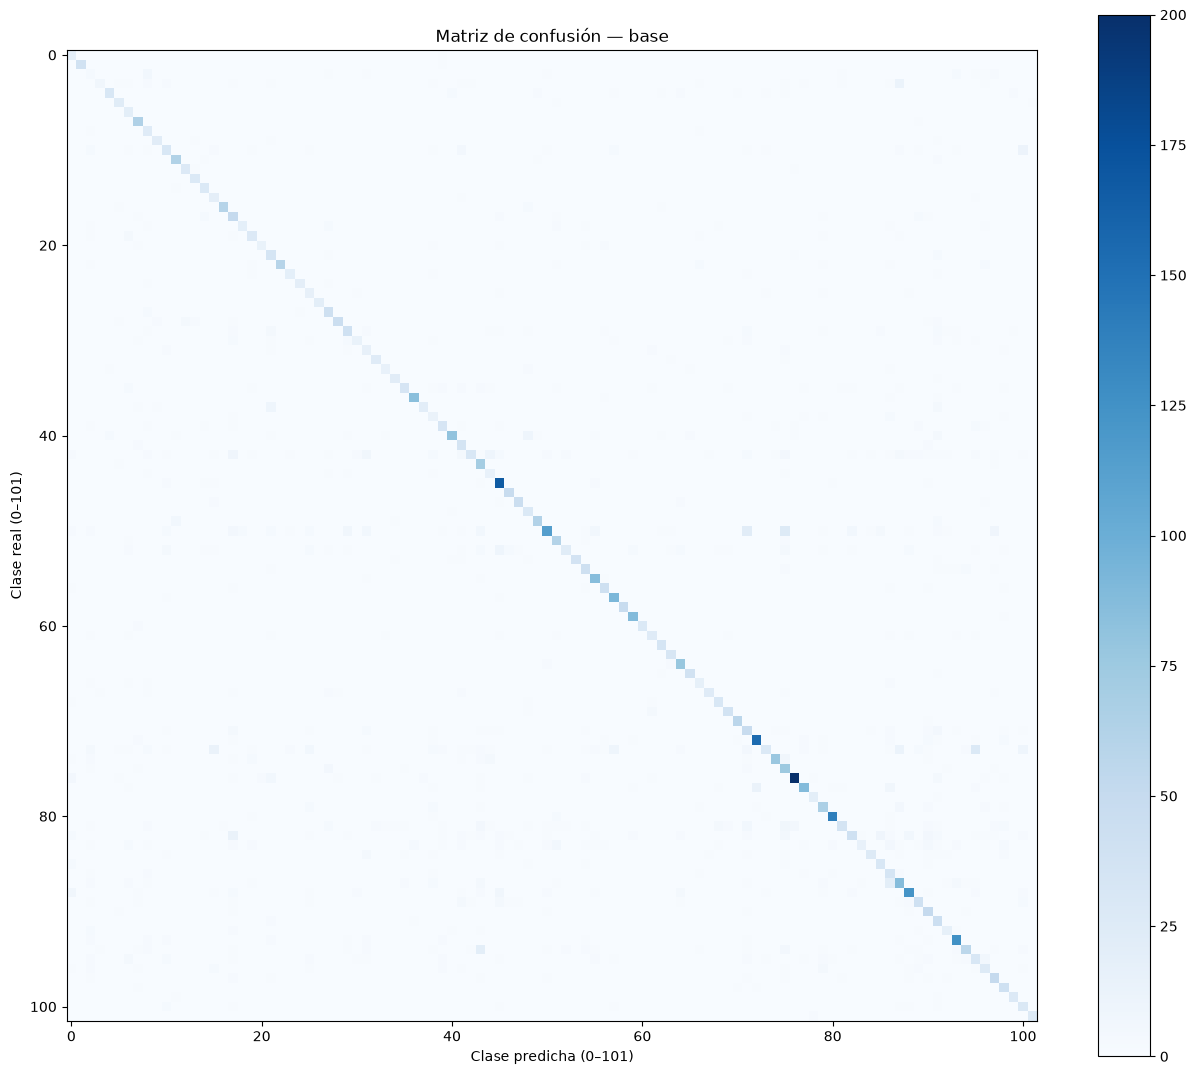

              precision    recall  f1-score   support

      Flor 1       0.41      0.90      0.56        20
      Flor 2       1.00      0.97      0.99        40
      Flor 3       0.08      0.15      0.10        20
      Flor 4       0.78      0.19      0.31        36
      Flor 5       0.89      0.69      0.78        45
      Flor 6       0.77      0.92      0.84        25
      Flor 7       0.44      1.00      0.62        20
      Flor 8       0.80      0.98      0.88        65
      Flor 9       0.41      0.92      0.57        26
     Flor 10       0.88      0.88      0.88        25
     Flor 11       0.54      0.46      0.50        67
     Flor 12       0.88      0.94      0.91        67
     Flor 13       0.87      0.93      0.90        29
     Flor 14       0.88      1.00      0.93        28
     Flor 15       0.78      0.97      0.86        29
     Flor 16       0.44      0.90      0.59        21
     Flor 17       0.98      0.92      0.95        65
     Flor 18       0.46    

In [13]:
# Curvas y matriz de confusión. Las filas son la clase real y las columnas la predicha.
plt.plot(historial_eval['train_loss'], label='Entrenamiento')
plt.plot(historial_eval['val_loss'], label='Validación')
plt.xlabel('Época'); plt.ylabel('Pérdida'); plt.legend(); plt.title(f'Curvas ({CONFIG})'); plt.show()
matriz_eval = confusion_matrix(reales_eval, predichos_eval, labels=list(range(len(clases))))
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(matriz_eval, cmap='Blues', interpolation='nearest'); fig.colorbar(im, ax=ax)
ax.set(xlabel='Clase predicha (0–101)', ylabel='Clase real (0–101)', title=f'Matriz de confusión — {CONFIG}')
fig.tight_layout(); plt.show()
reporte_eval = classification_report(reales_eval, predichos_eval, labels=list(range(len(clases))), target_names=clases, zero_division=0, output_dict=True)
print(classification_report(reales_eval, predichos_eval, labels=list(range(len(clases))), target_names=clases, zero_division=0))
sin_diagonal = matriz_eval.copy(); np.fill_diagonal(sin_diagonal, 0)
pares = sorted([(int(sin_diagonal[a, b]), a, b) for a in range(len(clases)) for b in range(len(clases)) if a != b and sin_diagonal[a, b] > 0], reverse=True)
print('Confusiones más frecuentes (real → predicha):')
for conteo, a, b in pares[:3]:
    print(f'  {clases[a]} → {clases[b]}: {conteo} casos')

Errores disponibles: 1507


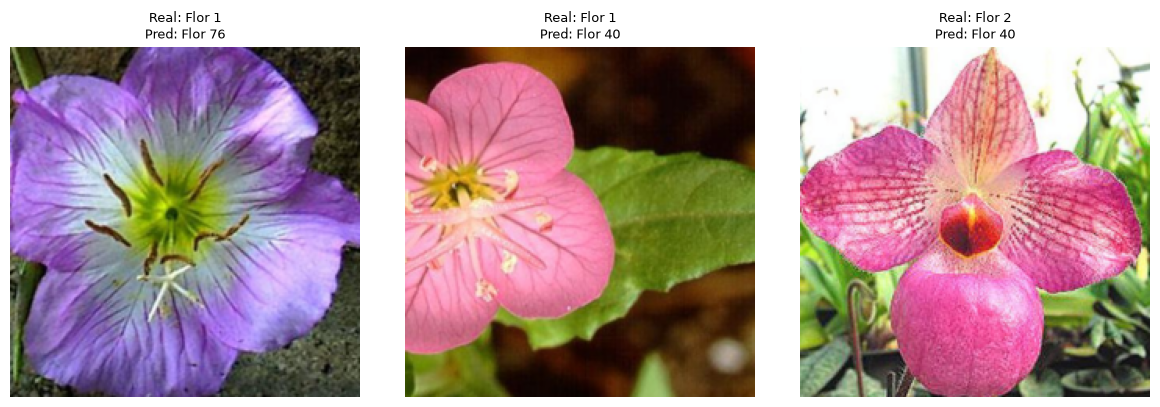

In [14]:
# Tres errores concretos con su imagen, para el análisis de la presentación.
errores = [i for i, (r, p) in enumerate(zip(reales_eval, predichos_eval)) if r != p]
print('Errores disponibles:', len(errores))
mean = np.array([0.485, 0.456, 0.406])[:, None, None]
std = np.array([0.229, 0.224, 0.225])[:, None, None]
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
for eje, i in zip(ejes, errores[:3]):
    imagen, etiqueta = prueba[i]
    eje.imshow(np.clip(imagen.numpy() * std + mean, 0, 1).transpose(1, 2, 0))
    eje.axis('off'); eje.set_title(f'Real: {clases[etiqueta]}\nPred: {clases[predichos_eval[i]]}', fontsize=9)
fig.tight_layout(); plt.show()

In [15]:
# Guardado con metadatos, carga estricta y demo de cinco imágenes no vistas en entrenamiento.
ruta_demo = Path(f'modelo_demo_{CONFIG}.pth')
torch.save({'pesos': modelo_eval.state_dict(), 'clases': clases, 'config': {'experimento': CONFIG, 'epocas': EPOCAS_EVAL, 'layer4': DESCONGELAR_LAYER4}, 'transformacion': str(transformacion), 'metricas': metricas_eval}, ruta_demo)
reconstruido = models.resnet18(weights=None)
for parametro in reconstruido.parameters():
    parametro.requires_grad = False
reconstruido.fc = nn.Linear(reconstruido.fc.in_features, len(clases))
if DESCONGELAR_LAYER4:
    for parametro in reconstruido.layer4.parameters():
        parametro.requires_grad = True
reconstruido.load_state_dict(torch.load(ruta_demo, map_location=device, weights_only=True)['pesos'])
reconstruido = reconstruido.to(device).eval()
print('Modelo recargado desde', ruta_demo)
x_demo, y_demo = next(iter(test_loader))
with torch.no_grad():
    original = modelo_eval(x_demo.to(device)).argmax(1).cpu()
    logits_cargado = reconstruido(x_demo.to(device))
    cargado = logits_cargado.argmax(1).cpu()
    probabilidades = torch.softmax(logits_cargado, dim=1).cpu()
print('Predicciones idénticas tras recargar:', bool(torch.equal(original, cargado)))
for i in range(5):
    valores, indices = probabilidades[i].topk(3)
    etiqueta = ', '.join(f'{clases[j]} ({v:.3f})' for v, j in zip(valores.tolist(), indices.tolist()))
    print(f'  ejemplo {i}: real={clases[y_demo[i].item()]} | pred={clases[cargado[i].item()]} | Top-3={etiqueta}')

Modelo recargado desde modelo_demo_base.pth


Predicciones idénticas tras recargar: True
  ejemplo 0: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.174), Flor 76 (0.064), Flor 19 (0.047)
  ejemplo 1: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.200), Flor 76 (0.109), Flor 86 (0.046)
  ejemplo 2: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.544), Flor 76 (0.090), Flor 87 (0.026)
  ejemplo 3: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.604), Flor 86 (0.115), Flor 76 (0.069)
  ejemplo 4: real=Flor 1 | pred=Flor 1 | Top-3=Flor 1 (0.913), Flor 65 (0.008), Flor 51 (0.008)


### Respuestas de la sección 9

1. **Qué se mide.** Exactitud Top-1, Top-3, pérdida y matriz de confusión sobre las 6,149 imágenes de prueba, con el modelo ya elegido por validación. La demo con cinco imágenes sirve para mostrar que la entrada y la salida funcionan, no para sustituir la evaluación.

2. **Qué se guarda.** Los pesos (`state_dict`), el orden de las 102 clases, la configuración, la representación de la transformación y las métricas. Sin esos metadatos los pesos no se pueden interpretar: la arquitectura tiene que reconstruirse igual y el preprocesamiento debe coincidir.

3. **Qué falta cuando llegue la configuración final.** Cambiar `CONFIG` a `'final'`, volver a correr esta sección y sustituir en la presentación las cifras base por las finales. La comparación entre ambas corridas no es un experimento nuevo: la decisión ya se tomó en validación con los seis ensayos de Persona 3.

4. **Límites.** Una predicción con confianza alta puede estar equivocada, y Top-3 alto no implica probabilidades calibradas. Tampoco se puede afirmar que el modelo generalice a flores fuera de las 102 clases del dataset.

## 10. Tabla para la defensa

| Momento | Configuración | Validación | Prueba Top-1 | Prueba Top-3 | Estado |
|---|---|---:|---:|---:|---|
| Avance mientras se espera | Base: `fc` entrenable, 5 épocas | 78.33 % | 75.49 % | 87.67 % | Corrida real en CPU |
| Entrega | Final: `layer4` + `fc`, 10 épocas | _la decide Persona 3_ | _se llena al correr_ | _se llena al correr_ | Pendiente de la decisión |

La fila base se llena con la corrida de esta sección. La fila final se llena al cambiar `CONFIG`; no se elige mirando la prueba.